# G93 Integrative Project - KPIs and Statistical Analysis

In this notebook, we will analyze everything related to the "Stations_Data.csv" file. The .csv file contains these variables:

- **Station**: {Berlin, Hamburg, Hannover, Frankfurt, Stuttgart}
- **Year**: (2015–2024)
- **Month**: (1–12)
- **Arrival of trains**: number
- **Iron**: tons
- **Coal**: tons
- **Steel**: tons
- **Vegetables**: tons
- **Cereals**: tons
- **Wool**: tons
- **Coffee**: tons
- **Cattle**: tons
- **Passengers**: number
- **Mail**: tons
- **Revenues**: Millions (€)
- **Expenses**: Millions (€)

The analysis will be divided into 4 user storys (US), which are the following:

1. **US15 - As a Player, I want to perform a statistical analysis of the aver age annual profit of a user-specified railway station.**
2. **US16 - As a Player, I want to perform a comparative analysis of passenger arrivals across all stations.**
3. **US17 - As a Player, I want to perform an analysis of the cargo arriving at each station using all recorded data.**
4. **US18 - As a Player, I want to perform the analysis of train distribution, passengers, and mail across different stations**

In each section (dedicated to one US), there will be a theoretical explanation about the statistical concepts that will be used, alongside the Python code to obtain the results.

## **US15: Statistical Analysis of the aver age annual profit of a user-specified railway station**

### **User Story Details**

As a Player, I want to perform a statistical analysis of the average annual profit of a user-specified railway station. In order to achieve this, a table with key descriptive measures: mean, standard deviation, median, and mode will be generated. Additionally, the analysis aims to identify outlier profits as well as to determine the most and least profitable years.

### **Theoretical Explanation**

#### What is a mean?

It's a quantity representing the "center" of a collection of numbers and is intermediate to the extreme values of the set of numbers.

#### What is a standard deviation?

It's a measure of the amount of variation of the values of a variable about its mean.

#### What is a median?

It's a set of numbers is the value separating the higher half from the lower half of a data sample, a population, or a probability distribution.

#### What is a mode?

It's a way of expressing, in a (usually) single number, important information about a random variable or a population.

#### What is an outlier?

It's a data point that differs significantly from other observations.

### **Code for US15**

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('Stations_Data.csv', sep=';')

# Convert values to float
num_cols = [
    'Revenues', 'Expenses'
]

for col in num_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.', regex=False),
        errors='coerce'
    )

# Obtain annual profit
df['Profit'] = df['Revenues'] - df['Expenses']
annual_profit = (
    df
    .groupby(['Station', 'Year'], as_index=False)['Profit']
    .sum()
)

# Input
station = input("Insert the station's name: ").strip()
station_data = annual_profit[annual_profit['Station'] == station]

if station_data.empty:
    print(f"No data found for station '{station}'.")
else:
    profits = station_data['Profit']
    years = station_data['Year']
    
    # Descriptive measures
    mean = profits.mean()
    std = profits.std()
    median = profits.median()
    mode = profits.mode().iloc[0] if not profits.mode().empty else None
    
    print(f"\nDescriptive measures for station: '{station}':")
    print(f"Mean: {mean:.2f}")
    print(f"Standard deviation: {std:.2f}")
    print(f"Median: {median:.2f}")
    print(f"Mode: {mode:.2f}")
    
    # Find outliers (IQR method)
    Q1 = profits.quantile(0.25)
    Q3 = profits.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = station_data[
        (station_data['Profit'] < lower) |
        (station_data['Profit'] > upper)
    ]
    
    print(f"\nFound outliers ({len(outliers)}):")
    if not outliers.empty:
        print(outliers[['Year', 'Profit']].to_string(index=False))
        
        # Most and least profitable years
        max_row = station_data.loc[profits.idxmax()]
        min_row = station_data.loc[profits.idxmin()]
        print(f"\nMost profitable year: {int(max_row['Year'])} -> {max_row['Profit']:.2f}")
        print(f"Least profitable year: {int(min_row['Year'])} -> {min_row['Profit']:.2f}")
    else:
        print("No outlier found.")

Insert the station's name:  Stuttgart



Descriptive measures for station: 'Stuttgart':
Mean: 1422.55
Standard deviation: 2315.38
Median: 524.01
Mode: -307.94

Found outliers (1):
 Year  Profit
 2023 7433.02

Most profitable year: 2023 -> 7433.02
Least profitable year: 2015 -> -307.94


## **US18: Distribution Analysis of Trains, Passengers, and Mail**

### **User Story Details**

As a Player, I want to perform the analysis of train distribution, passengers, and mail across different stations. Using all recorded data, this distribution will be visually represented through three pie charts, providing a clear and comprehensive overview of how these elements are allocated among the stations.

### **Theoretical Explanation**

#### What is a Pie Chart?

A pie chart represents the relative frequency or percentage of categorical data. In our case, the categories we are interested in are the total number of train arrivals, total passenger counts, and total mail (in tons) recorded across all stations.

### **Code for US18**

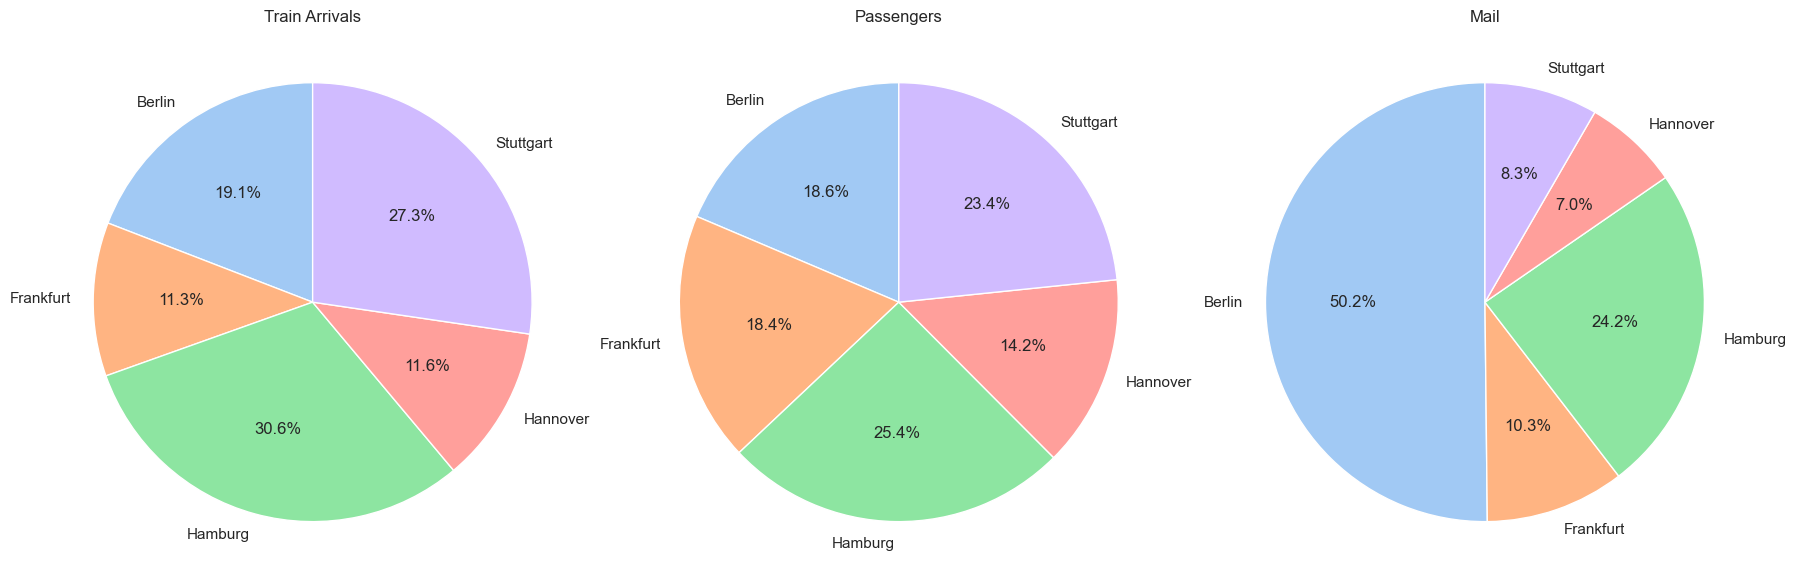

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

caminho_ficheiro = 'Stations_Data.csv'
df = pd.read_csv(caminho_ficheiro, sep=';')

# Transforming data into numbers, by replacing ',' with '.'
colunas = ['Arrivals', 'Passengers', 'Mail']
for col in colunas:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.'),
        errors='coerce'
    )

# Group the information by Station
df_agrupado = df.groupby('Station', as_index=False).agg({
    'Arrivals': 'sum',
    'Passengers': 'sum',
    'Mail': 'sum'
})

# Creating the figure with 3 pie charts in it
plt.figure(figsize=(18, 6))

categorias = ['Arrivals', 'Passengers', 'Mail']
titulos = ['Train Arrivals', 'Passengers', 'Mail']

for i, categoria in enumerate(categorias, 1):
    plt.subplot(1, 3, i)
    data = df_agrupado[['Station', categoria]].copy()
    
    plt.pie(
        data[categoria],
        labels=data['Station'],
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('pastel')
    )
    plt.axis('equal')
    plt.title(titulos[i - 1])

plt.tight_layout()
plt.show()
